In [1]:
import torch
print("GPU Aktif mi?:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Kullanılan GPU:", torch.cuda.get_device_name(0))

GPU Aktif mi?: True
Kullanılan GPU: Tesla T4


In [2]:
import os
import kagglehub
import pandas as pd

# Token'ı ortam değişkeni olarak tanımla
os.environ["KAGGLE_API_TOKEN"] = "YOUR_KAGGLE_API_TOKEN"

# Veri setini indirme
path = kagglehub.dataset_download("agrigorev/clothing-dataset-full")
print("Veri seti yolu:", path)
print("Klasör içeriği:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "images.csv"))
print("\nToplam satır sayısı:", len(df))
print("\nSınıf dağılımı:")
print(df["label"].value_counts())

100%|██████████| 6.50G/6.50G [06:02<00:00, 19.3MB/s]

Extracting files...


Veri seti yolu: /root/.cache/kagglehub/datasets/agrigorev/clothing-dataset-full/versions/1
Klasör içeriği: ['images_compressed', 'images_original', 'images.csv']

Toplam satır sayısı: 5403

Sınıf dağılımı:
label
T-Shirt       1011
Longsleeve     699
Pants          692
Shoes          431
Shirt          378
Dress          357
Outwear        312
Shorts         308
Not sure       228
Hat            171
Skirt          155
Polo           120
Undershirt     118
Blazer         109
Hoodie         100
Body            69
Other           67
Top             43
Blouse          23
Skip            12
Name: count, dtype: int64


In [3]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.model_selection import train_test_split

img_dir = os.path.join(path, "images_compressed")

# En net 10 sınıfı seçtik ve belirsiz etiketleri çıkardık
selected_classes = [
    "T-Shirt", "Longsleeve", "Pants", "Shoes", "Shirt",
    "Dress", "Outwear", "Shorts", "Hat", "Skirt"
]
df_clean = df[df["label"].isin(selected_classes)].copy()

# Dosya yollarını oluştur ve gerçekten var olan görselleri tut
df_clean["filepath"] = df_clean["image"].apply(lambda x: os.path.join(img_dir, f"{x}.jpg"))
df_clean = df_clean[df_clean["filepath"].apply(os.path.exists)].reset_index(drop=True)

# Sınıf isimlerini sayısal etiketlere (0-9) çevir (kıyafetlerin türleri)
class_names = sorted(df_clean["label"].unique())
label2idx = {name: i for i, name in enumerate(class_names)}
idx2label = {i: name for i, name in enumerate(class_names)}
df_clean["target"] = df_clean["label"].map(label2idx)

print(f"Temizlenmiş toplam görsel sayısı: {len(df_clean)}")
print(f"Sınıflar ({len(class_names)} adet): {class_names}")

#  %70 Train, %15 Validation, %15 Test olarak böl
train_df, temp_df = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean["target"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["target"], random_state=42
)

print(f"Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}")

# Görüntü dönüşümleri (ResNet-18 için 224x224 ve ImageNet normalizasyonu)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# PyTorch Dataset Sınıfı
class ClothingDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, "filepath"]
        label = self.df.loc[idx, "target"]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, label

#  DataLoader'lar
BATCH_SIZE = 32

train_loader = DataLoader(ClothingDataset(train_df, train_transforms), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader   = DataLoader(ClothingDataset(val_df, val_test_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(ClothingDataset(test_df, val_test_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("DataLoader'lar başarıyla hazırlandı!")

Temizlenmiş toplam görsel sayısı: 4514
Sınıflar (10 adet): ['Dress', 'Hat', 'Longsleeve', 'Outwear', 'Pants', 'Shirt', 'Shoes', 'Shorts', 'Skirt', 'T-Shirt']
Train: 3159 | Validation: 677 | Test: 678
DataLoader'lar başarıyla hazırlandı!


In [4]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Cihaz ayarı (GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Eğitim cihazı:", device)

# 1. Pretrained ResNet-18 modelini yükle ve son katmanı 10 sınıfa uyarla
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, len(class_names))
model = model.to(device)

# 2. Hiperparametreler, Loss ve Optimizer
EPOCHS = 10
LEARNING_RATE = 1e-4
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

# 3. Eğitim ve Doğrulama Döngüsü
best_val_acc = 0.0
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

start_time = time.time()

for epoch in range(EPOCHS):
    # --- EĞİTİM ADIMI ---
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = correct / total

    # --- DOĞRULAMA ADIMI  ---
    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch [{epoch+1:02d}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc*100:.2f}%")

    # En iyi doğrulama başarımını kaydediyoruz
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "best_clothing_model.pth")

total_training_time = time.time() - start_time
print(f"\nEğitim tamamlandı! Toplam süre: {total_training_time:.2f} saniye ({total_training_time/60:.2f} dakika)")
print(f"En iyi Validation Accuracy: {best_val_acc*100:.2f}%")

Eğitim cihazı: cuda
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 52.8MB/s]


Epoch [01/10] | Train Loss: 0.9029, Train Acc: 71.19% | Val Loss: 0.4124, Val Acc: 87.74%
Epoch [02/10] | Train Loss: 0.3126, Train Acc: 90.60% | Val Loss: 0.3130, Val Acc: 90.25%
Epoch [03/10] | Train Loss: 0.1764, Train Acc: 95.28% | Val Loss: 0.2950, Val Acc: 91.73%
Epoch [04/10] | Train Loss: 0.1110, Train Acc: 96.90% | Val Loss: 0.3199, Val Acc: 90.40%
Epoch [05/10] | Train Loss: 0.0734, Train Acc: 98.13% | Val Loss: 0.2892, Val Acc: 90.40%
Epoch [06/10] | Train Loss: 0.0572, Train Acc: 98.61% | Val Loss: 0.3100, Val Acc: 91.14%
Epoch [07/10] | Train Loss: 0.0574, Train Acc: 98.42% | Val Loss: 0.2917, Val Acc: 91.29%
Epoch [08/10] | Train Loss: 0.0458, Train Acc: 98.77% | Val Loss: 0.3433, Val Acc: 89.51%
Epoch [09/10] | Train Loss: 0.0402, Train Acc: 99.08% | Val Loss: 0.3236, Val Acc: 90.40%
Epoch [10/10] | Train Loss: 0.0277, Train Acc: 99.15% | Val Loss: 0.2763, Val Acc: 91.43%

Eğitim tamamlandı! Toplam süre: 234.96 saniye (3.92 dakika)
En iyi Validation Accuracy: 91.73%


=== TEST KÜMESİ SONUÇLARI ===
Test Accuracy : 88.64%
Precision     : 88.97%
Recall        : 88.64%
F1-Score      : 88.59%

=== SINIF BAZLI DETAYLI RAPOR ===
              precision    recall  f1-score   support

       Dress     0.9778    0.8148    0.8889        54
         Hat     0.8400    0.8400    0.8400        25
  Longsleeve     0.7647    0.8667    0.8125       105
     Outwear     0.8684    0.7021    0.7765        47
       Pants     0.9524    0.9615    0.9569       104
       Shirt     0.8654    0.7895    0.8257        57
       Shoes     0.9552    0.9846    0.9697        65
      Shorts     0.8837    0.8261    0.8539        46
       Skirt     0.8148    0.9565    0.8800        23
     T-Shirt     0.9108    0.9408    0.9256       152

    accuracy                         0.8864       678
   macro avg     0.8833    0.8683    0.8730       678
weighted avg     0.8897    0.8864    0.8859       678

Ortalama Inference Time (1 görsel): 7.21 ms


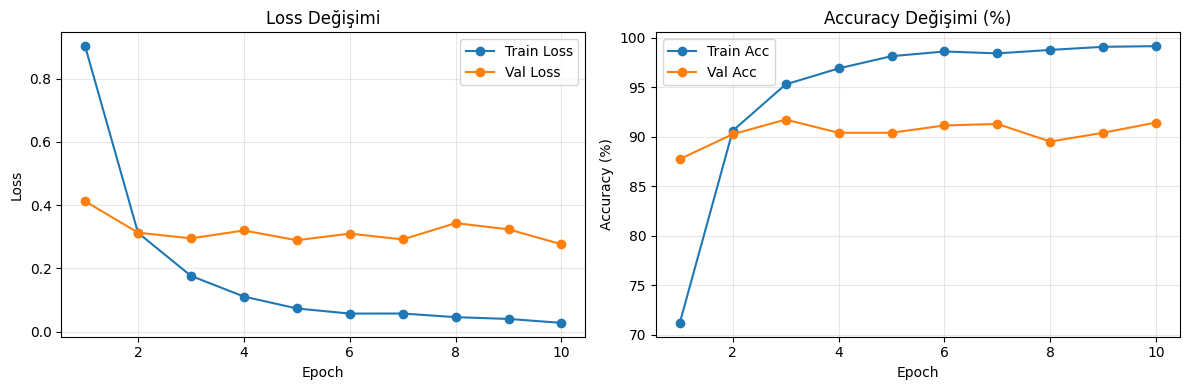

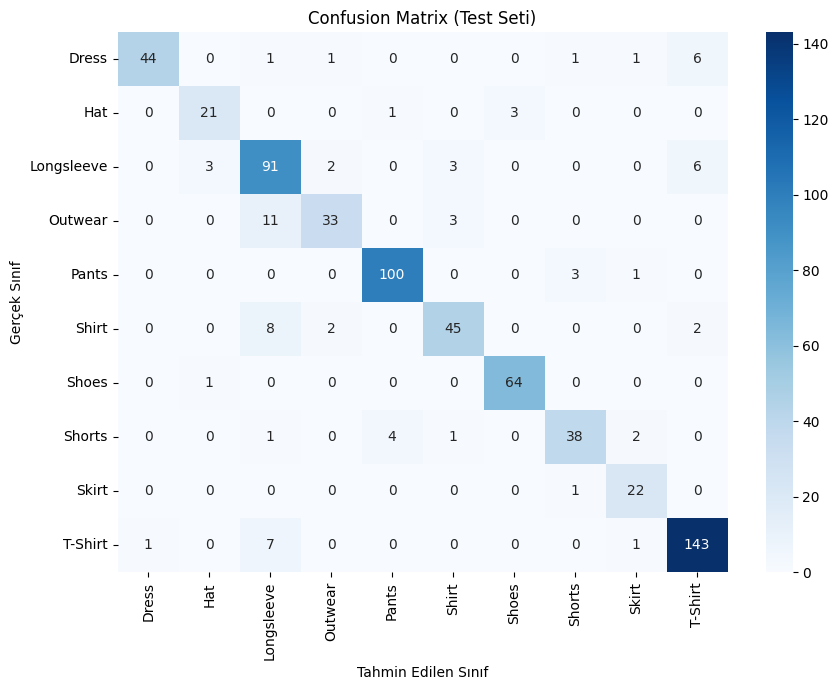

In [5]:
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

# 1. En iyi model ağırlıklarını yükle
model.load_state_dict(torch.load("best_clothing_model.pth", map_location=device))
model.eval()

# 2. Test kümesi üzerinde tahminleri al
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 3. Metriklerini hesapla
test_acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average="weighted")

print(f"=== TEST KÜMESİ SONUÇLARI ===")
print(f"Test Accuracy : {test_acc*100:.2f}%")
print(f"Precision     : {precision*100:.2f}%")
print(f"Recall        : {recall*100:.2f}%")
print(f"F1-Score      : {f1*100:.2f}%\n")

print("=== SINIF BAZLI DETAYLI RAPOR ===")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

# 4. Tek görsel için Inference Time ölçümü (GPU warm-up ile ortalama ms)
dummy_input = torch.randn(1, 3, 224, 224).to(device)
with torch.no_grad():
    for _ in range(10):  # GPU ısınma turu
        _ = model(dummy_input)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_inf = time.time()
    for _ in range(100):
        _ = model(dummy_input)
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    avg_inference_ms = ((time.time() - start_inf) / 100) * 1000

print(f"Ortalama Inference Time (1 görsel): {avg_inference_ms:.2f} ms")

# 5. Eğitim / Doğrulama Loss ve Accuracy Grafikleri
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, EPOCHS + 1)

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
axes[0].plot(epochs_range, history["val_loss"], label="Val Loss", marker="o")
axes[0].set_title("Loss Değişimi")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, [a*100 for a in history["train_acc"]], label="Train Acc", marker="o")
axes[1].plot(epochs_range, [a*100 for a in history["val_acc"]], label="Val Acc", marker="o")
axes[1].set_title("Accuracy Değişimi (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150)
plt.show()

# 6. Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix (Test Seti)")
plt.xlabel("Tahmin Edilen Sınıf")
plt.ylabel("Gerçek Sınıf")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [6]:
!pip install -q gradio

import time
import gradio as gr
import torch
import torch.nn.functional as F
from PIL import Image

model.load_state_dict(torch.load("best_clothing_model.pth", map_location=device))
model.eval()

def predict_clothing(image):
    if image is None:
        return None, "Lütfen bir görsel yükleyin."

    # Görüntüyü modele uygun formata getir
    img = Image.fromarray(image).convert("RGB")
    input_tensor = val_test_transforms(img).unsqueeze(0).to(device)

    # Tahmin ve süre ölçümü
    start_t = time.time()
    with torch.no_grad():
        outputs = model(input_tensor)
        probs = F.softmax(outputs, dim=1)[0]
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    inf_ms = (time.time() - start_t) * 1000

    # Sınıf olasılıklarını sözlük olarak döndür
    confidences = {class_names[i]: float(probs[i]) for i in range(len(class_names))}
    time_text = f"Tahmin Süresi (Inference Time): {inf_ms:.2f} ms"

    return confidences, time_text

# Gradio Arayüzü
demo = gr.Interface(
    fn=predict_clothing,
    inputs=gr.Image(label="Kıyafet Fotoğrafı Yükle"),
    outputs=[
        gr.Label(num_top_classes=3, label="Model Tahmini (İlk 3 Sınıf)"),
        gr.Textbox(label="Performans Bilgisi")
    ],
    title="Kıyafet Türü Sınıflandırma (ResNet-18)",
    description="Bir kıyafet fotoğrafı yükleyin; model 10 farklı kıyafet kategorisi arasından tahmin yapsın ve işlem süresini göstersin."
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://acab487f30c1c13920.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
